# 01 · Exploración y calidad del corpus `dragons_rag`

Este notebook narra el perfilado de la Fase A. **No recalcula nada**: lee los artefactos que genera el contenedor `pipeline`, de modo que cada cifra sale del mismo código que corre en Docker.

```bash
docker compose --profile tools run --rm pipeline python -m scripts.profile_corpus --input data/documentos_rag.parquet
```

- **Fuente de las cifras:** `reports/eda/profile.json` y `reports/eda/tables/*.csv`.
- **Figuras:** `reports/eda/figures/`.
- **Conclusiones y decisiones:** [`reports/eda/resumen.md`](../reports/eda/resumen.md).

Solo se muestran agregados, nunca texto del corpus.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
EDA = ROOT / 'reports' / 'eda'
profile = json.loads((EDA / 'profile.json').read_text(encoding='utf-8'))
table = lambda name: pd.read_csv(EDA / 'tables' / f'{name}.csv')
figure = lambda name: display(Image(filename=str(EDA / 'figures' / f'{name}.png')))
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

run = profile['run']
print('Ejecución:', run['created_at_utc'], f"({run['duration_seconds']} s)")
print('Parquet:', run['parquet']['path'], '| sha256', run['parquet']['sha256'][:16] + '…', '| filas', f"{run['parquet']['rows']:,}")
print('Encoder:', run['encoder'])
print('Versiones:', run['versions'])

Ejecución: 2026-11-02T23:59:03+00:00 (164.5 s)
Parquet: data/documentos_rag.parquet | sha256 f4a669f17eaedd35… | filas 169,248
Encoder: {'model': 'intfloat/multilingual-e5-small', 'query_prefix': 'query: ', 'passage_prefix': 'passage: ', 'normalize': True, 'max_tokens': 512}
Versiones: {'python': '3.12.16', 'pandas': '2.3.3', 'pyarrow': '23.0.1', 'numpy': '2.5.4', 'scipy': '1.18.1', 'matplotlib': '3.11.2', 'lingua-language-detector': '2.2.0', 'datasketch': '2.0.0', 'transformers': '5.22.1', 'sentence-transformers': '5.7.0', 'open_corpus_co_es': '0.1.1a4'}


## 1. Integridad (A1)

El archivo se verifica sin modificarlo:

- su sha256 frente al manifiesto y al catálogo de `open_corpus_co_es`;
- el esquema y los valores no vacíos por columna frente al manifiesto;
- la unicidad de los identificadores;
- el recálculo de las columnas derivadas (`char_count = len(text)`, `word_count = len(text.split())` y `text_sha256` en UTF-8).

In [2]:
integrity = profile['integrity']
{k: integrity[k] for k in ('sha256_matches_manifest', 'sha256_matches_catalog', 'columns', 'schema_ok',
                           'document_id_unique', 'recount_mismatches', 'counts_match_published', 'nonempty_diff_vs_manifest')}

{'sha256_matches_manifest': True,
 'sha256_matches_catalog': True,
 'columns': 33,
 'schema_ok': True,
 'document_id_unique': True,
 'recount_mismatches': {'char_count': 0, 'word_count': 0, 'text_sha256': 0},
 'counts_match_published': True,
 'nonempty_diff_vs_manifest': {}}

In [3]:
display(table('integridad_conteos'))
display(table('integridad_unicidad'))
table('integridad_completitud')

,field,value,observed,expected,diff
0,total,total,169248,169248,0
1,collection_name,bluesky_posts,64670,64670,0
2,collection_name,url_crawls,104578,104578,0
3,source,bluesky,64670,64670,0
4,source,gdelt,1198,1198,0
5,source,media_cloud,103380,103380,0


,column,non_null,distinct,duplicate_rows
0,document_id,169248,169248,0
1,mongo_id,169248,169248,0
2,url,169248,169021,227
3,uri,169248,169021,227
4,text_sha256,169248,154477,14771


,column,rows,nulls,empty,whitespace_only,nonempty,manifest_nonempty,diff_vs_manifest
0,document_id,169248,0,0,0,169248,169248,0
1,text,169248,0,0,0,169248,169248,0
2,collection_name,169248,0,0,0,169248,169248,0
3,title,169248,64670,4,0,104574,104574,0
4,url,169248,0,0,0,169248,169248,0
5,source,169248,0,0,0,169248,169248,0
6,source_type,169248,99326,0,0,69922,69922,0
7,language,169248,13137,0,0,156111,156111,0
8,country_key,169248,99326,0,0,69922,69922,0
9,created_at,169248,23,0,0,169225,169225,0


Los conteos de valores no vacíos coinciden con el manifiesto en todas las columnas. Los nulos que se ven son estructurales: `title`, `strategy` y `final_url` no existen en Bluesky, y `author_handle` no existe en prensa. Las fechas (`created_at`, `synced_at`) vienen como texto, así que hay que interpretarlas antes de usarlas.

## 2. Longitud y tokens del encoder (A2)

In [4]:
lengths = table('distribucion_longitudes')
display(lengths.pivot(index='metric', columns='collection_name', values='p50').rename(columns=lambda c: f'p50 {c}'))
display(lengths[lengths['metric'] == 'n_tokens'])
table('distribucion_tokens_umbral')

collection_name,p50 bluesky_posts,p50 total,p50 url_crawls
metric,,,
char_count_calc,232,2367,3882
n_tokens,62,543,896
word_count_calc,35,371,622


,collection_name,metric,n,mean,min,p5,p50,p95,p99,max
2,bluesky_posts,n_tokens,64670,58.9489,10,23,62,86.0000,136.0000,323
5,url_crawls,n_tokens,104578,"1,081.9800",14,309,896,"2,335.0000","4,211.0000",88532
8,total,n_tokens,169248,691.0770,10,32,543,"1,921.0000","3,512.0000",88532


,collection_name,n,share_gt_256,share_gt_512
0,bluesky_posts,64670,0.0000,0.0000
1,url_crawls,104578,0.9655,0.8320
2,total,169248,0.5966,0.5141


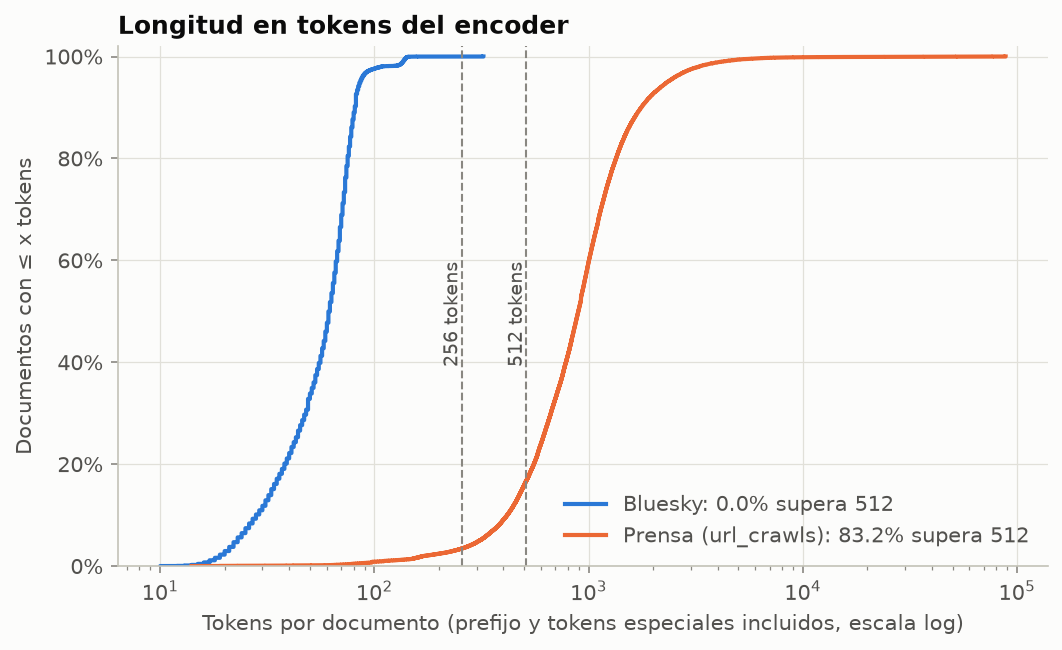

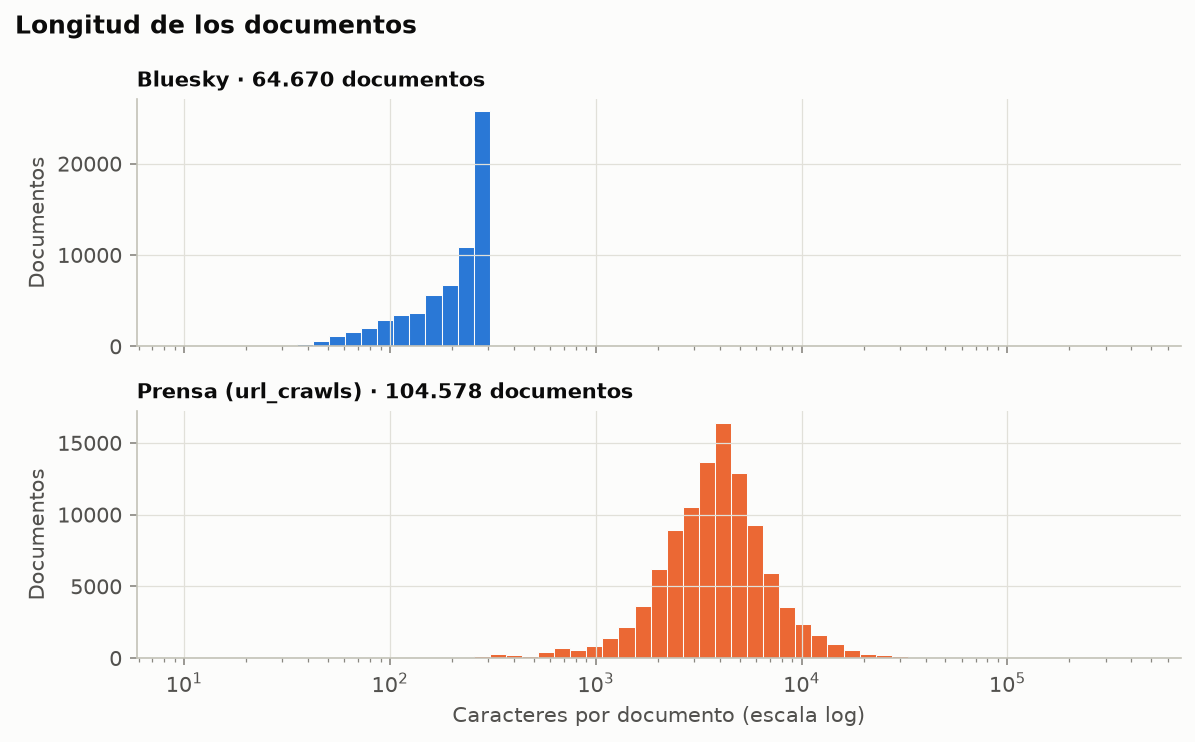

In [5]:
figure('tokens_ecdf')
figure('longitud_caracteres')

Los tokens se cuentan con `app.embeddings.count_tokens`: el prefijo `passage: `, el texto y los tokens especiales, sin truncar. Es la misma medida que usará la Fase B para los chunks.

- **Ningún post de Bluesky alcanza el tope de 512 tokens.** Pueden ir como chunk único.
- **La mayoría de las noticias lo supera.** Si se codificaran enteras, el encoder truncaría en silencio el resto del texto.

## 3. Idioma declarado frente a detectado (A2)

,collection_name,n,declared_null,detected_null,compared,agreement
0,bluesky_posts,64670,13137,2,51531,0.9446
1,url_crawls,104578,0,15,104563,0.9775
2,total,169248,13137,17,156094,0.9666


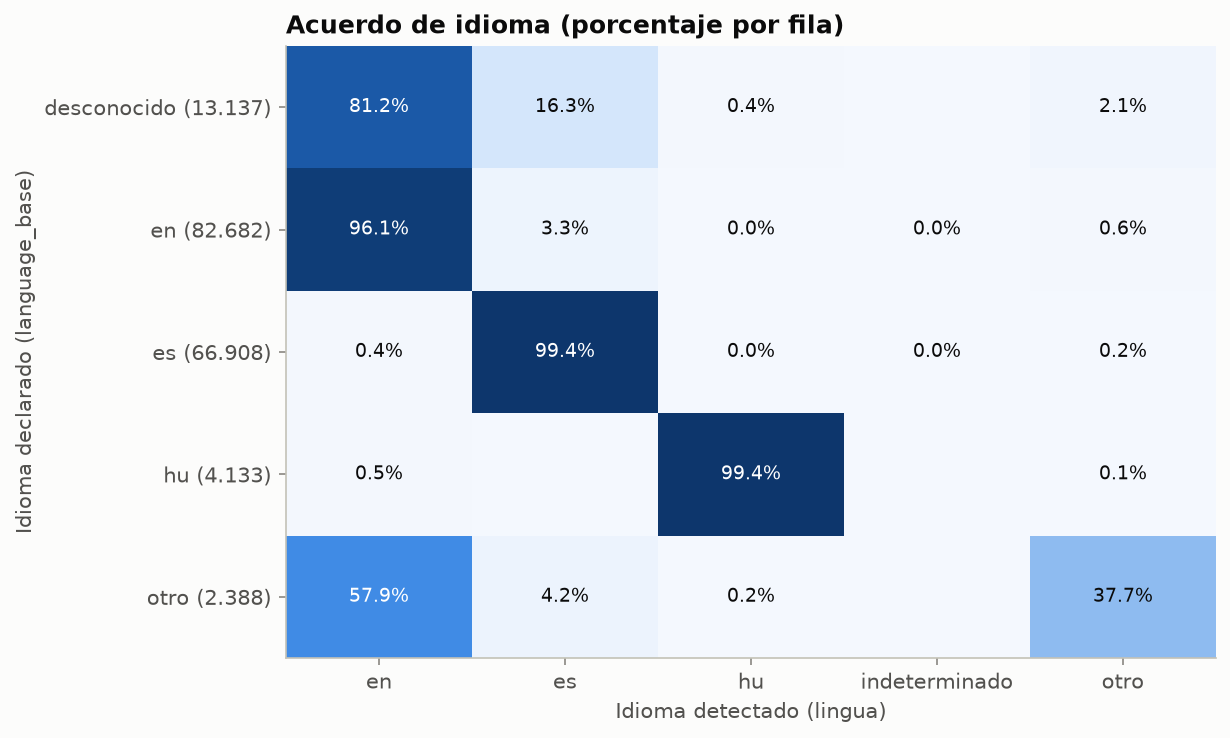

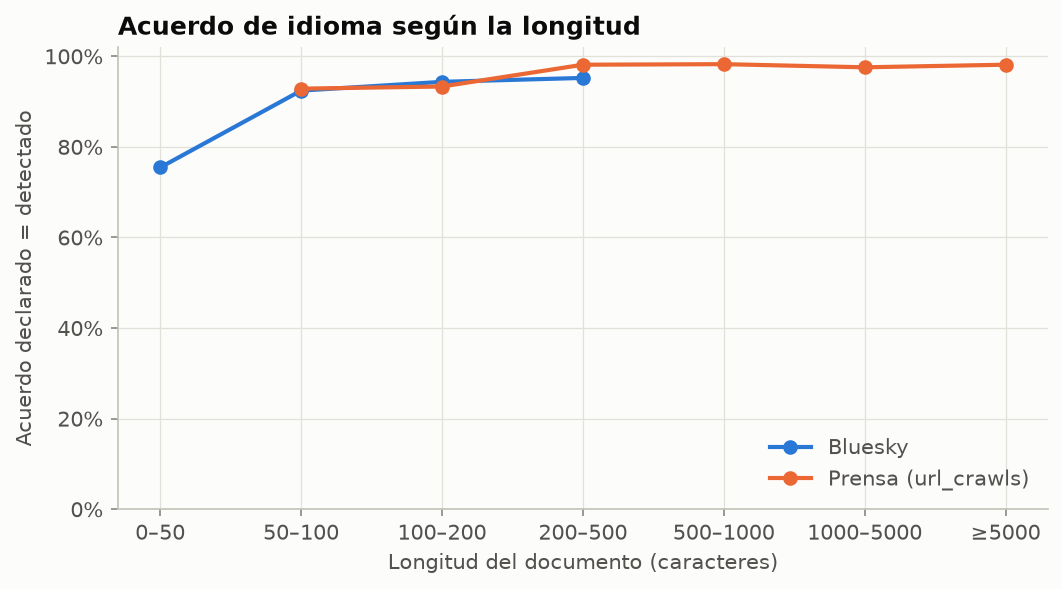

In [6]:
display(table('idioma_acuerdo'))
figure('idioma_matriz')
figure('idioma_acuerdo_longitud')

- **Alto acuerdo en en, es y hu.** Los idiomas minoritarios declarados se detectan mayoritariamente como inglés.
- **Bluesky trae un bloque grande sin idioma declarado**, que el detector reparte entre inglés y español.
- **En textos de menos de 50 caracteres el acuerdo cae.** Ahí ninguna de las dos fuentes es del todo fiable.

## 4. Fechas (A2)

,collection_name,n,nulo,solo_fecha,fecha_hora,min,p50,max,after_synced,after_version,before_plausible_start
0,bluesky_posts,64670,0,0,64670,2008-07-19 22:26:45+00:00,2026-04-30 08:03:48.209500160+00:00,2026-09-11 23:58:04.917000+00:00,0,0,344
1,url_crawls,104578,23,99297,5258,2006-08-24 00:00:00+00:00,2023-12-07 00:00:00+00:00,2026-09-21 18:03:56.341143+00:00,0,0,0
2,total,169248,23,99297,69928,2006-08-24 00:00:00+00:00,2025-03-29 11:29:02.092999936+00:00,2026-09-21 18:03:56.341143+00:00,0,0,344


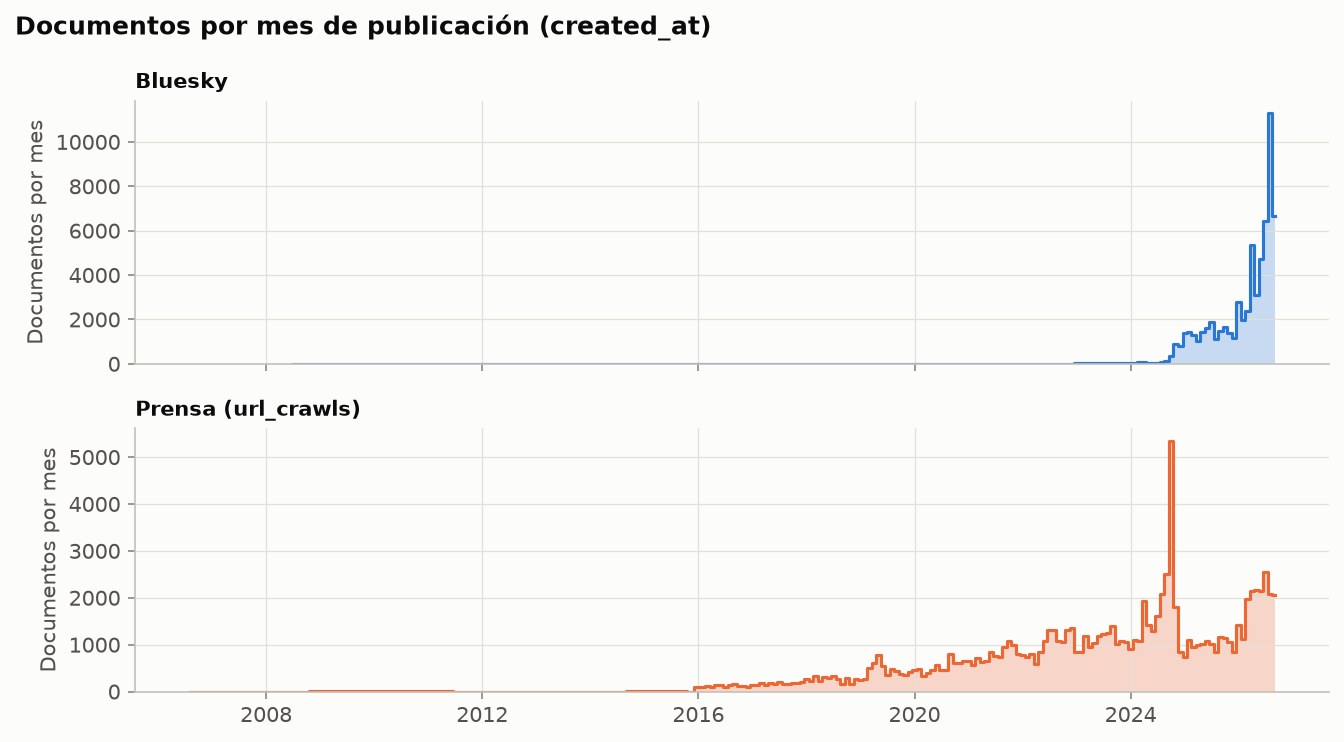

collection_name,bluesky_posts,url_crawls
period,,
2015,0.0003,0.0002
2016,0.0003,0.0138
2017,0.0008,0.0196
2018,0.0006,0.0299
2019,0.0007,0.0510
2020,0.0008,0.0602
2021,0.0007,0.0896
2022,0.0000,0.1174
2023,0.0000,0.1253


In [7]:
dates = table('fechas_resumen')
display(dates[['collection_name', 'n', 'nulo', 'solo_fecha', 'fecha_hora', 'min', 'p50', 'max',
               'after_synced', 'after_version', 'before_plausible_start']])
figure('fechas_mensual')
table('fechas_anual').pivot(index='period', columns='collection_name', values='share').fillna(0).tail(12)

- **Prensa:** casi siempre trae solo la fecha, sin hora.
- **Bluesky:** se concentra en 2025-2026. Las fechas anteriores a 2023 son retroactivas, porque la plataforma no existía.
- **Ninguna fecha es posterior a la sincronización** ni a la versión del corpus.

## 5. Duplicados exactos y casi duplicados (A3)

In [8]:
display(table('duplicados_exactos_coleccion'))
display(table('duplicados_exactos_grupos_top').head(10))
table('duplicados_exactos_dominio').head(10)

,collection_name,rows,unique_texts,extra_rows,rows_in_duplicate_groups,rows_in_cross_collection_groups,extra_share
0,bluesky_posts,64670,56277,8393,9972,0,0.1298
1,url_crawls,104578,98200,6378,9233,0,0.0610
2,total,169248,154477,14771,19205,0,0.0873


,rank,group_size,collection_name,collections,domains,top_domain,char_count
0,1,839,bluesky_posts,1,1,bsky.app,289
1,2,674,bluesky_posts,1,1,bsky.app,162
2,3,526,url_crawls,1,2,www.rcnradio.com,3949
3,4,399,bluesky_posts,1,1,bsky.app,246
4,5,347,bluesky_posts,1,1,bsky.app,258
5,6,268,url_crawls,1,2,confidencialcolombia.com,5320
6,7,255,bluesky_posts,1,1,bsky.app,215
7,8,214,bluesky_posts,1,1,bsky.app,161
8,9,171,bluesky_posts,1,1,bsky.app,246
9,10,159,bluesky_posts,1,1,bsky.app,198


,collection_name,url_domain,rows,extra_rows,extra_share
0,bluesky_posts,bsky.app,64670,8393,0.1298
1,url_crawls,www.diariodelsur.com.co,1568,678,0.4324
2,url_crawls,www.hsbnoticias.com,1380,662,0.4797
3,url_crawls,extra.com.co,1942,603,0.3105
4,url_crawls,www.rcnradio.com,497,495,0.9960
5,url_crawls,diariodelcauca.com.co,493,332,0.6734
6,url_crawls,www.independent.co.uk,4799,237,0.0494
7,url_crawls,www.infobae.com,19766,221,0.0112
8,url_crawls,www.theguardian.com,7216,221,0.0306
9,url_crawls,www.dailymail.co.uk,3305,214,0.0648


In [9]:
display(table('casi_duplicados_tipos'))
table('casi_duplicados_resumen')

,type,pairs,jaccard_median,length_ratio_median,share
0,exacto,4031,1.0000,1.0000,0.9166
1,mismo_dominio,362,0.9375,0.8837,0.0823
2,otro_dominio,5,0.9743,0.9870,0.0011


,collection_name,documents,with_near_duplicate,with_any_duplicate,share_near_duplicate,share_any_duplicate
0,bluesky_posts,3821,123,385,0.0322,0.1008
1,url_crawls,6179,14,176,0.0023,0.0285
2,total,10000,137,561,0.0137,0.0561


Los duplicados exactos se concentran en dos fenómenos:

- **Posts de plantilla de campañas en Bluesky:** el texto que se comparte al firmar una petición.
- **Páginas de prensa que no son artículos:** portadas o perfiles capturados cientos de veces, por ejemplo en `rcnradio.com` y `confidencialcolombia.com`.

Los casi duplicados no exactos son pocos, y en prensa corresponden sobre todo a notas sindicadas.

## 6. URLs, ruido y boilerplate (A4)

In [10]:
display(table('urls_resumen'))
display(table('urls_tracking').head(8))
table('ruido_coleccion').pivot(index='label', columns='collection_name', values='documents')

,collection_name,n,null,valid,https,with_query,with_tracking,duplicated,final_url_differs
0,bluesky_posts,64670,0,64670,64670,0,0,0,0
1,url_crawls,104578,0,104578,98425,5636,2050,227,16570
2,total,169248,0,169248,163095,5636,2050,227,16570


,collection_name,param,documents
0,url_crawls,utm_source,2002
1,url_crawls,utm_medium,1920
2,url_crawls,utm_campaign,1746
3,url_crawls,utm_term,42
4,url_crawls,utm_content,34
5,url_crawls,fbclid,23
6,url_crawls,utm_hp_ref,2
7,url_crawls,utm_brand,1


collection_name,bluesky_posts,total,url_crawls
label,,,
carácter de reemplazo (U+FFFD),2,17,15
entidades HTML,19,19,0
etiquetas HTML,8,119,111
mojibake,0,1049,1049
muy corto (< 5 palabras),651,653,2
solo URL,116,116,0
solo emojis o símbolos,0,0,0
vacío o solo espacios,0,0,0


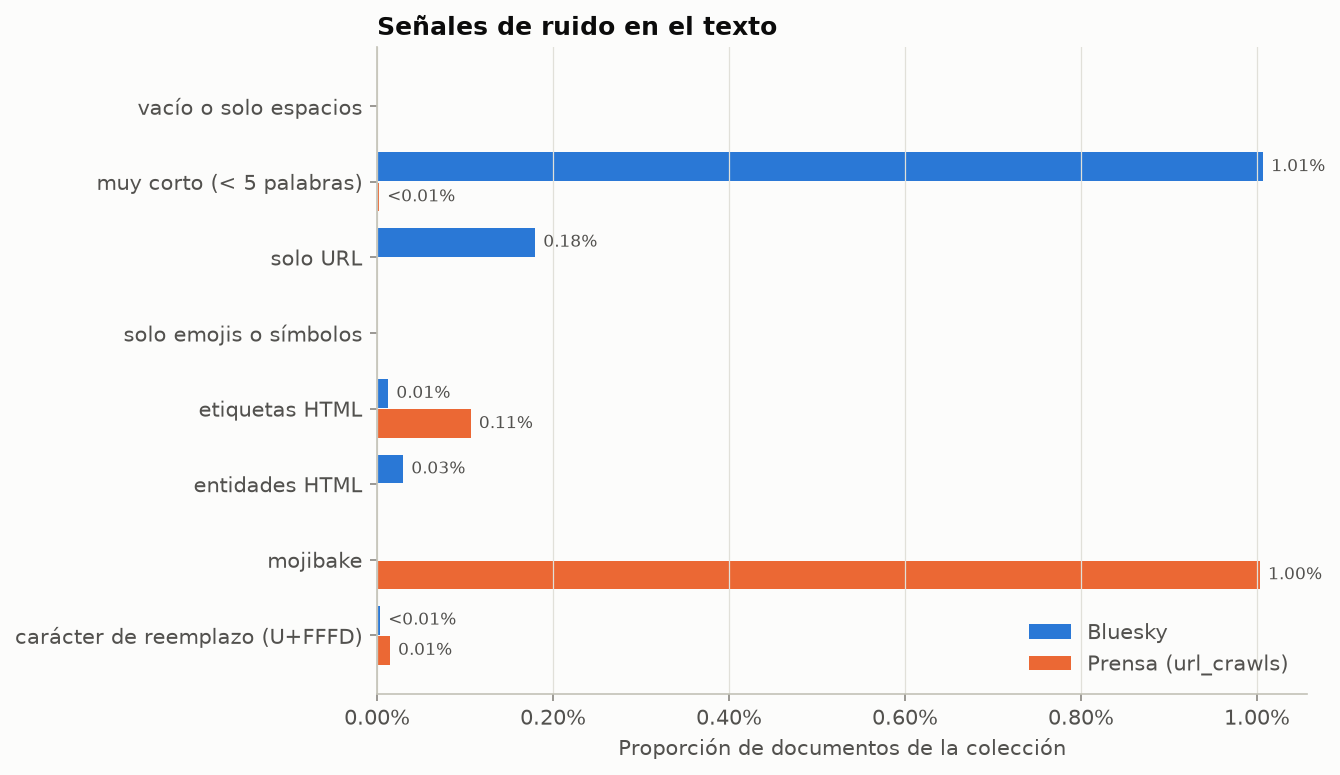

,flag,url_domain,documents,flagged,share_of_domain,share_of_flagged
0,is_short,bsky.app,64670,651,0.0101,0.9969
1,is_short,house.jrj.com.cn,2,2,1.0000,0.0031
2,only_urls,bsky.app,64670,116,0.0018,1.0000
3,has_html_tag,www.infobae.com,19766,101,0.0051,0.8487
4,has_html_tag,bsky.app,64670,8,0.0001,0.0672
5,has_html_tag,www.ibtimes.co.uk,288,5,0.0174,0.0420
6,has_html_tag,www.elespectador.com,5456,2,0.0004,0.0168
7,has_html_tag,www.contagioradio.com,68,1,0.0147,0.0084
8,has_html_tag,www.elcolombiano.com,948,1,0.0011,0.0084
9,has_html_tag,www.irishnews.com,68,1,0.0147,0.0084


,url_domain,documents,with_boilerplate,mean_boilerplate_share,boilerplate_lines,share_with_boilerplate
0,www.infobae.com,19766,8410,0.2524,627,0.4255
1,www.eltiempo.com,12229,9517,0.3122,79,0.7782
2,www.theguardian.com,7216,1116,0.0141,19,0.1547
3,www.elespectador.com,5456,696,0.0356,8,0.1276
4,www.independent.co.uk,4799,633,0.0204,79,0.1319
5,theconversation.com,3721,291,0.0066,10,0.0782
6,www.dailymail.co.uk,3305,2569,0.0442,125,0.7773
7,extra.com.co,1942,43,0.0077,4,0.0221
8,www.larepublica.co,1716,1697,0.2340,64,0.9889
9,www.diariodelsur.com.co,1568,53,0.0116,4,0.0338


In [11]:
figure('ruido')
display(table('ruido_dominio'))
table('boilerplate_dominio')

- **El mojibake es casi exclusivo de un dominio** (`www.elcolombiano.com`): es un problema de la fuente, no del corpus en general.
- **El boilerplate se concentra en pocos medios.** Conviene excluir sus líneas al segmentar en vez de reescribir el texto, para que los offsets sigan siendo del original.

## 7. Sesgos de recolección (A5)

,collection_name,domains,top5_share,top20_share,hhi
0,url_crawls,978,0.4730,0.6951,0.0642


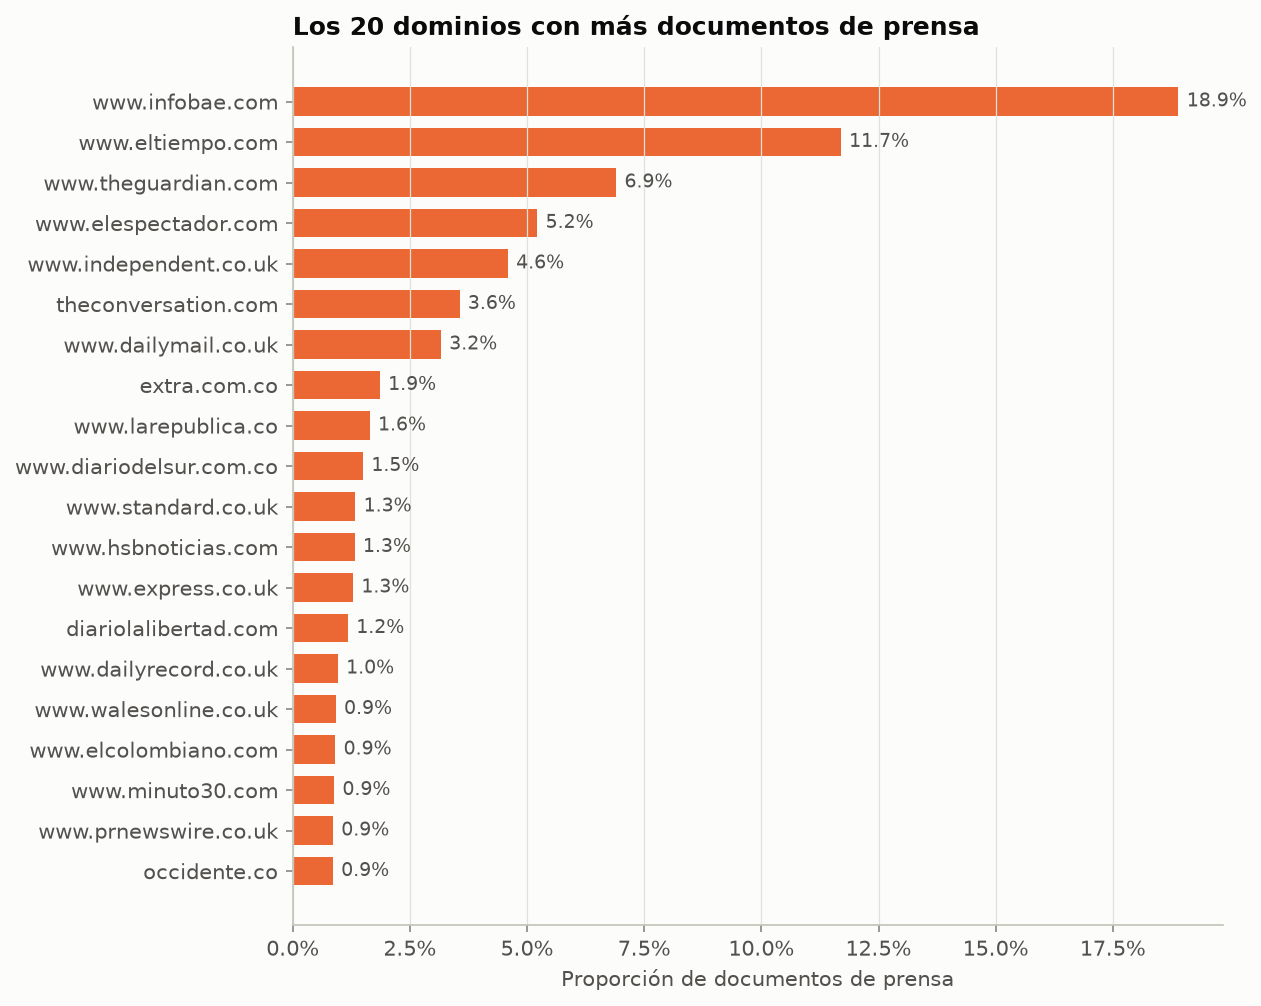

,field,collection_name,value,documents,share
50,collection_keyword_label,bluesky_posts,Emotional resonance — negative,10403,0.1609
58,collection_keyword_label,bluesky_posts,"Structural context, power and information",7585,0.1173
57,collection_keyword_label,bluesky_posts,Responsibility and blame,5794,0.0896
46,collection_keyword_label,bluesky_posts,"Contestation, backlash and disinformation",5652,0.0874
52,collection_keyword_label,bluesky_posts,"Hope, pride and positive affect",5525,0.0854
48,collection_keyword_label,bluesky_posts,Drivers and pressures,5449,0.0843
43,collection_keyword_label,bluesky_posts,Calls to action and mobilisation,5438,0.0841
60,collection_keyword_label,url_crawls,(nulo),104578,1.0000
11,country_key,bluesky_posts,united_kingdom,38699,0.5984
9,country_key,bluesky_posts,colombia,15621,0.2415


In [12]:
display(table('sesgo_concentracion_dominios'))
figure('dominios_top')
fields = table('sesgo_campos_adquisicion')
fields[fields['share'] >= 0.05].sort_values(['field', 'collection_name', 'documents'], ascending=[True, True, False])

- **Prensa:** la mitad viene de cinco dominios.
- **Campos de adquisición (`country_key`, `keyword_family`, `collection_keyword_label`, `strategy`):** describen la consulta de recolección y **no son etiquetas semánticas**. Por ejemplo, `country_key = hungary` no implica que el post esté en húngaro.

## 8. Muestras reproducibles (A6)

In [13]:
print({k: v['size'] for k, v in profile['samples'].items()})
display(table('muestras_distribucion'))
table('muestras_representatividad')

{'2000': 2000, '10000': 10000, 'full': 169248}


,stratum,corpus_documents,sample_documents,corpus_share,sample_share,diff,sample
0,url_crawls|es,63420,750,0.3747,0.3750,0.0003,2000
1,bluesky_posts|en,45773,541,0.2704,0.2705,0.0001,2000
2,url_crawls|en,36909,436,0.2181,0.2180,-0.0001,2000
3,bluesky_posts|desconocido,13137,155,0.0776,0.0775,-0.0001,2000
4,url_crawls|hu,4062,48,0.0240,0.0240,-0.0000,2000
5,bluesky_posts|es,3488,41,0.0206,0.0205,-0.0001,2000
6,bluesky_posts|otro,2201,26,0.0130,0.0130,-0.0000,2000
7,url_crawls|otro,187,2,0.0011,0.0010,-0.0001,2000
8,bluesky_posts|hu,71,1,0.0004,0.0005,0.0001,2000
9,url_crawls|es,63420,3747,0.3747,0.3747,-0.0000,10000


,check,group,value,p_value,sample
0,proporciones collection_name,total,0.0001,NaN,2000
1,proporciones language_base,total,0.0002,NaN,2000
2,KS char_count,bluesky_posts,0.0323,0.4014,2000
3,mediana char_count muestra/corpus,bluesky_posts,0.9720,NaN,2000
4,KS char_count,url_crawls,0.0293,0.2390,2000
5,mediana char_count muestra/corpus,url_crawls,1.0173,NaN,2000
6,proporciones collection_name,total,0.0000,NaN,10000
7,proporciones language_base,total,0.0001,NaN,10000
8,KS char_count,bluesky_posts,0.0134,0.5341,10000
9,mediana char_count muestra/corpus,bluesky_posts,0.9871,NaN,10000


Las muestras de 2.000 y 10.000 documentos están estratificadas por colección × idioma declarado y anidadas (la de 2.000 está contenida en la de 10.000). Sus proporciones y su distribución de longitudes reproducen las del corpus.

Las decisiones que se derivan de todo este perfilado están en [`reports/eda/resumen.md`](../reports/eda/resumen.md) (sección 7).